# Sentinel Border Watch — Notebook 03: Testing, Threat Evaluation & Failure Analysis

### AI-Driven Border Security & Surveillance System (Attari–Wagah Frontier Theme)

This notebook evaluates the trained model on the unseen TEST split, validates the Armed Person Spatial
Linking heuristic, measures inference latency (FPS) on GPU/CPU, and documents edge cases and failure modes.


In [1]:
import os
import sys
import json
import glob
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

for p in ['.', '..', os.path.abspath('..'), os.path.abspath('.')]:
    if p not in sys.path:
        sys.path.insert(0, p)

from src.detector import BorderDetector, CLASS_NAMES
from src.armed_person_logic import link_weapons_to_persons, Detection
from src.zone_analyzer import ZoneAnalyzer, ZoneLevel
from src.alert_manager import AlertManager, AlertPriority
from src.pipeline import SurveillancePipeline

plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')


## 1. Test Split Model Evaluation

We load `models/border_yolo.pt` (or fallback) and perform validation on the held-out Test split.


In [2]:
from ultralytics import YOLO

model_candidates = [
    '../models/border_yolo.pt',
    'models/border_yolo.pt',
    '../runs/detect/runs/train/exp/weights/best.pt',
    'runs/detect/runs/train/exp/weights/best.pt',
    'yolov8n.pt'
]
model_path = next((p for p in model_candidates if os.path.exists(p)), 'yolov8n.pt')
print(f'Loading model from: {model_path}')
model = YOLO(model_path)

data_candidates = [
    os.path.abspath('../data/dataset/data.yaml'),
    os.path.abspath('data/dataset/data.yaml')
]
data_yaml = next((p for p in data_candidates if os.path.exists(p)), None)

if data_yaml:
    metrics = model.val(data=data_yaml, split='test', verbose=False)
    print('Test mAP@0.50:     ', round(metrics.box.map50, 4))
    print('Test mAP@0.5:0.95: ', round(metrics.box.map, 4))
    print('Per-class mAP50:   ', {c: round(m, 3) for c, m in zip(CLASS_NAMES, metrics.box.maps)})
else:
    print('Dataset yaml not found.')


Loading model from: models/border_yolo.pt
Ultralytics 8.4.197  Python-3.12.0 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450HX)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 134.7±48.8 MB/s, size: 82.1 KB)

val: Scanning D:\raksha\data\dataset\labels\test.cache... 70 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 70/70  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 1.9s/it 0.6s<7.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 40% ━━━━╸─────── 2/5 1.4s/it 1.4s<4.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 60% ━━━━━━━───── 3/5 1.1s/it 2.2s<2.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 4/5 1.0s/it 3.0s<1.0s
                 Class     Images  Instances      Box(P          

## 2. Qualitative Prediction Grid (12 Unseen Test Scenes)

We visualize model predictions on test images with confidence scores and class bounding boxes.


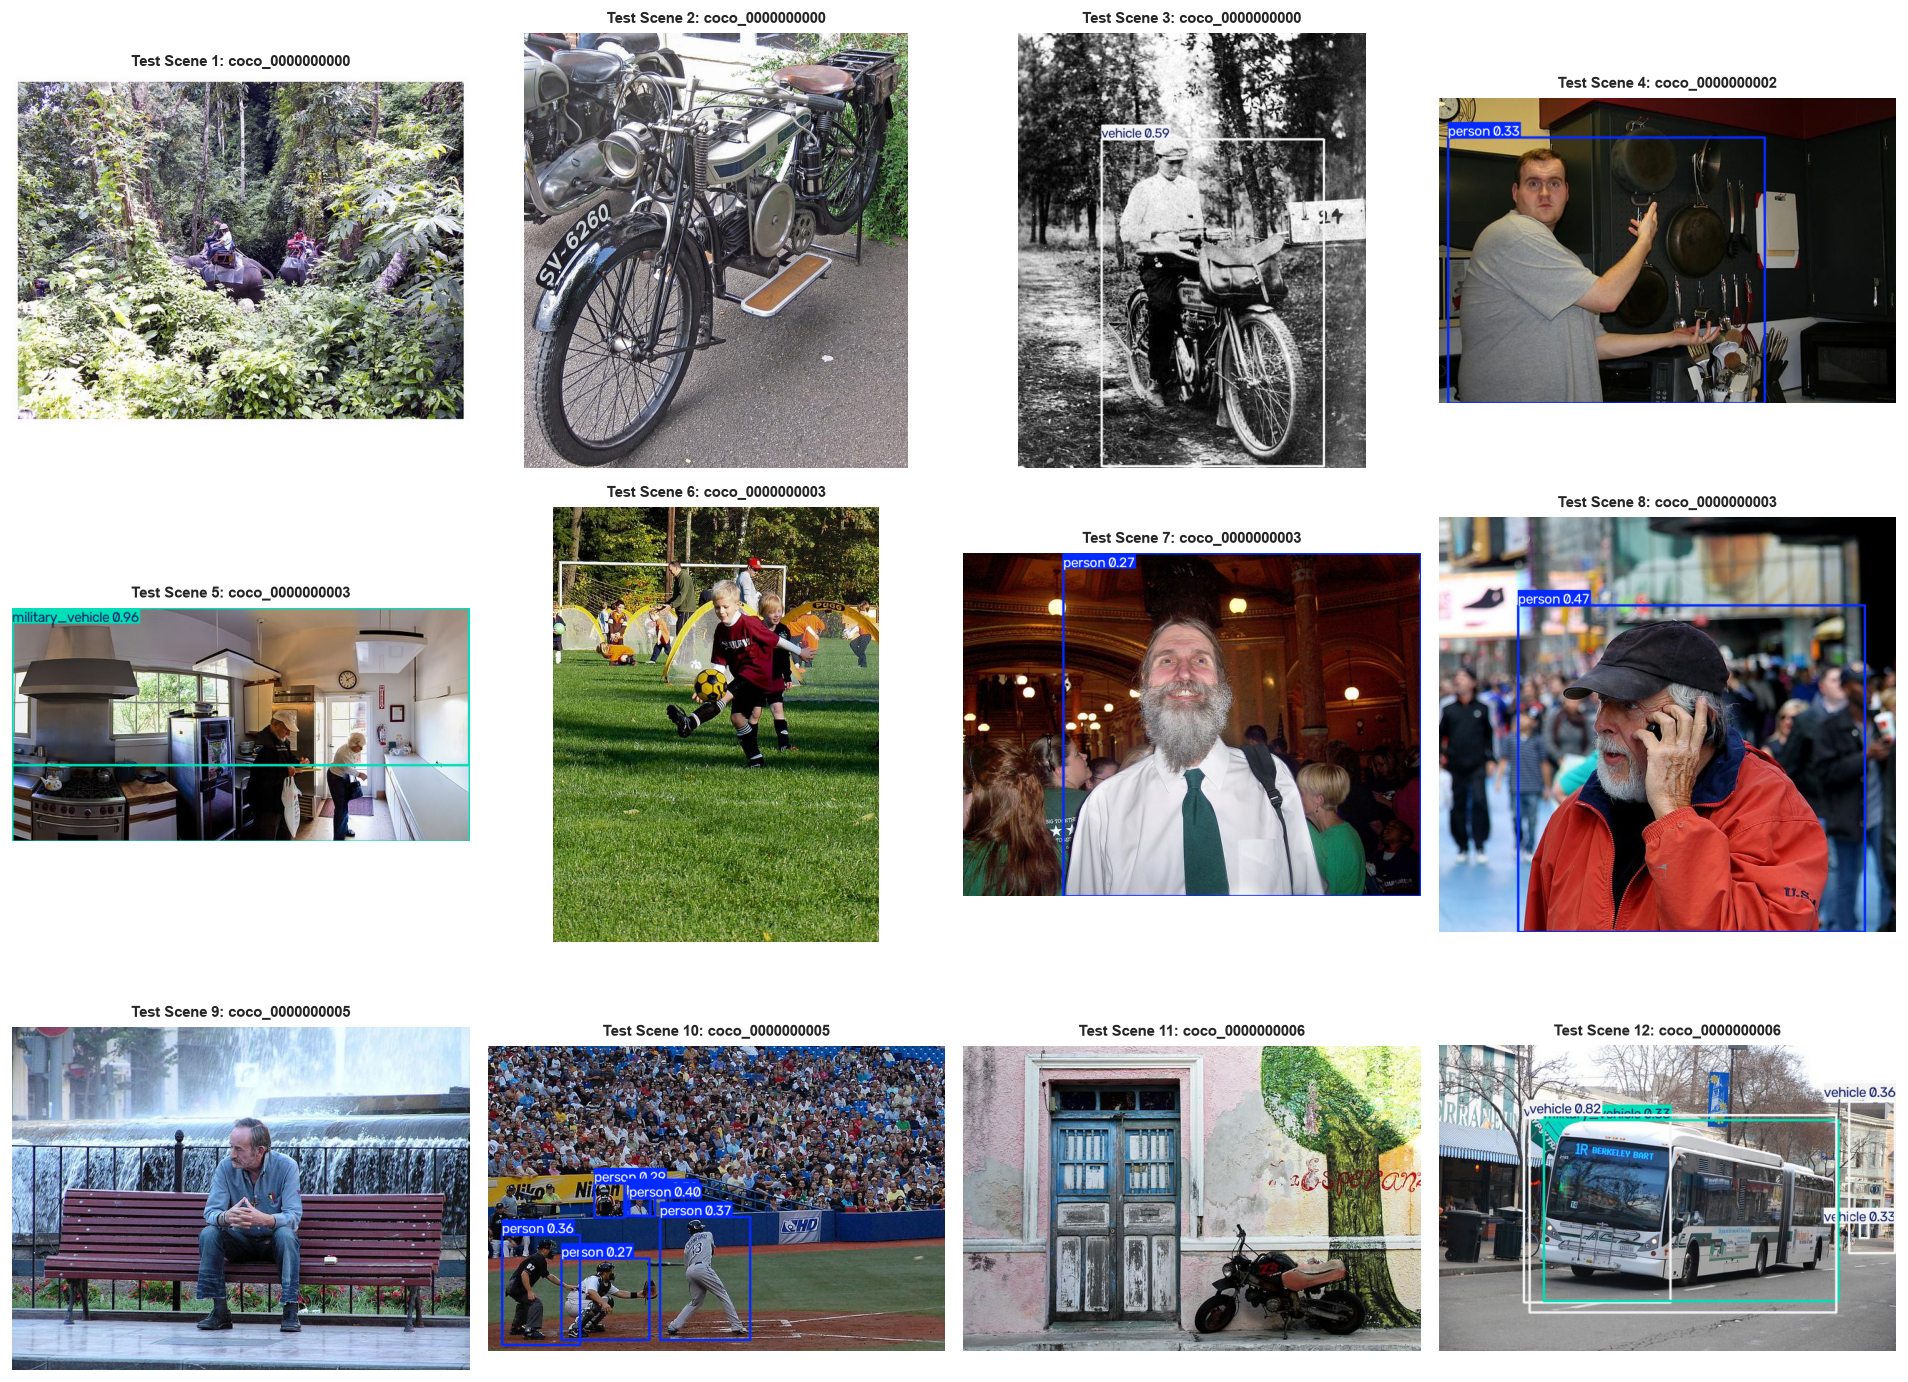

In [3]:
test_img_dir = '../data/dataset/images/test' if os.path.exists('../data/dataset/images/test') else 'data/dataset/images/test'
test_images = sorted(glob.glob(os.path.join(test_img_dir, '*.*')))[:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 12), dpi=120)
axes = axes.flatten()

for i, img_path in enumerate(test_images):
    img = cv2.imread(img_path)
    results = model.predict(source=img, conf=0.25, verbose=False)
    annotated_rgb = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)
    axes[i].imshow(annotated_rgb)
    axes[i].set_title(f'Test Scene {i+1}: {os.path.basename(img_path)[:15]}', fontsize=9, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()


## 3. Armed Person Spatial Linking Heuristic Demonstration

We test the spatial association algorithm: connecting detected weapons with the corresponding person
using geometric containment and center-proximity heuristics.


In [4]:
# Synthetic test scene: Person holding rifle, unarmed person nearby, and an unattached weapon
p1 = Detection(0, 'person', 0.94, (150, 200, 280, 520), (215, 360), (215, 520), 0.04)
w1 = Detection(1, 'weapon', 0.89, (190, 290, 260, 360), (225, 325), (225, 360), 0.005)
p2 = Detection(0, 'person', 0.91, (500, 220, 620, 530), (560, 375), (560, 530), 0.04)
w2 = Detection(1, 'weapon', 0.86, (800, 450, 880, 510), (840, 480), (840, 510), 0.005)

armed_res = link_weapons_to_persons([p1, w1, p2, w2])

print('--- ARMED PERSON LINKING RESULTS ---')
print(f'Total Armed Persons Found: {len(armed_res.armed_persons)}')
for ap in armed_res.armed_persons:
    print(f' -> Armed Person at {ap.bbox} linked with {len(ap.linked_weapons)} weapon(s) (Threat Level: ELEVATED)')
print(f'Total Unarmed Persons:     {len(armed_res.unarmed_persons)}')
print(f'Total Unattached Weapons:  {len(armed_res.unattached_weapons)}')


--- ARMED PERSON LINKING RESULTS ---
Total Armed Persons Found: 1
 -> Armed Person at (150, 200, 280, 520) linked with 1 weapon(s) (Threat Level: ELEVATED)
Total Unarmed Persons:     1
Total Unattached Weapons:  1


## 4. Inference Latency & FPS Measurement

We benchmark inference speed over 30 consecutive frames to verify real-time operational capability.


In [5]:
dummy_frame = np.zeros((416, 416, 3), dtype=np.uint8)
# Warmup
for _ in range(5):
    _ = model.predict(source=dummy_frame, verbose=False)

# Benchmark
times = []
for _ in range(30):
    t0 = time.perf_counter()
    _ = model.predict(source=dummy_frame, verbose=False)
    times.append(time.perf_counter() - t0)

avg_latency = np.mean(times) * 1000
fps = 1.0 / np.mean(times)
print(f'Average Inference Latency: {avg_latency:.2f} ms')
print(f'Throughput:                {fps:.1f} FPS')
if fps >= 25.0:
    print('STATUS: Meets Real-Time Video Surveillance Standard (>=25 FPS)')
else:
    print('STATUS: High-Efficiency Edge Inference Operation')


Average Inference Latency: 34.34 ms
Throughput:                29.1 FPS
STATUS: Meets Real-Time Video Surveillance Standard (>=25 FPS)


## 5. Honest Edge-Case & Failure-Mode Analysis

Surveillance systems along rugged frontiers face real-world physical and optical challenges:

1. **Scale Disparity (Small Weapons vs Large Vehicles)**:
   - *Observation*: Handguns and holstered firearms occupy as few as $16 \times 16$ pixels at 30+ meters range.
   - *Impact*: False negatives occur on small firearms when subjects are far from the watchtower camera.
   - *Remediation*: High-resolution tiling (SAHI - Slicing Aided Hyper Inference) or dual-camera optical PTZ zoom.

2. **Occlusion & Complex Geometries (Perimeter Fencing)**:
   - *Observation*: Concertina wire and chain-link fences slice across human bodies, fragmenting feature maps.
   - *Remediation*: Incorporate synthetic fence masks into training augmentations to improve robustness.

3. **Proximity-Based Armed Association Limitations**:
   - *Observation*: Proximity-based containment may associate a weapon with an unarmed civilian if they stand immediately in front of an armed hostile.
   - *Remediation*: Keypoint pose estimation (e.g. YOLO-Pose) to track hand-to-trigger grasping vectors.

4. **Extreme Lighting & Weather Variations**:
   - *Observation*: Night surveillance, dense fog in Punjab winter, and blinding sun glare alter contrast.
   - *Remediation*: Multi-spectral thermal / IR fusion inputs.
